In [2]:

# Step 1: Import Python library
import pandas as pd

# Step 2: Load Medical Laboratory Dataset
df = pd.read_csv(
    "/content/CKD_Dataset_Excel_Compatible.csv"
)

# Step 3: Display the first 5 patient records
print("CHRONIC KIDNEY DISEASE DATASET")
display(df.head())

# Step 4: Check total patients and columns
print("Total Patients:", df.shape[0])
print("Total Columns:", df.shape[1])

# Step 5: Check laboratory test names
print("Laboratory Parameters:")
print(df.columns.tolist())


CHRONIC KIDNEY DISEASE DATASET


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


Total Patients: 400
Total Columns: 25
Laboratory Parameters:
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']


In [3]:

# STEP 2: Check missing values in laboratory dataset

print("TOTAL PATIENT RECORDS:", len(df))

print("\nDATASET INFORMATION:")
df.info()

print("\nMISSING VALUES IN EACH COLUMN:")
print(df.isnull().sum())

print("\nCKD AND NON-CKD PATIENTS:")
print(df['class'].value_counts())

print("\nSTATISTICAL SUMMARY:")
display(df.describe())


TOTAL PATIENT RECORDS: 400

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    object 
 6   pc      335 non-null    object 
 7   pcc     396 non-null    object 
 8   ba      396 non-null    object 
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    object 
 19  dm      398 non-null    object 
 20  cad     398 non-null    obj

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000,329.000000,294.000000,269.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437,38.884498,8406.122449,4.707435
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587,8.990105,2944.474190,1.025323
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000,9.000000,2200.000000,2.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000,32.000000,6500.000000,3.900000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000,40.000000,8000.000000,4.800000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000,45.000000,9800.000000,5.400000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000,54.000000,26400.000000,8.000000


In [4]:

# STEP 3: DATA CLEANING

import pandas as pd
import numpy as np

# Create a copy of original data
df_clean = df.copy()

# Replace question marks and blank strings
df_clean = df_clean.replace(
    r"^\s*(\?|nan)?\s*$",
    np.nan,
    regex=True
)

# Clean text columns
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert laboratory measurements to numeric
numeric_columns = [
    'age', 'bp', 'sg', 'al', 'su', 'bgr',
    'bu', 'sc', 'sod', 'pot', 'hemo',
    'pcv', 'wc', 'rc', 'wbcc', 'rbcc'
]

for col in numeric_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors='coerce'
        )

# Show missing values
print("MISSING VALUES AFTER CLEANING:")
print(df_clean.isnull().sum())

# Check patient records
print("\nTotal patients:", len(df_clean))

print("\nCKD CLASSIFICATION:")
print(df_clean['class'].value_counts())

print("\nCLEANED DATASET PREVIEW:")
display(df_clean.head())


MISSING VALUES AFTER CLEANING:
age        9
bp        12
sg        47
al        46
su        49
rbc      152
pc        65
pcc        4
ba         4
bgr       44
bu        19
sc        17
sod       87
pot       88
hemo      52
pcv       71
wbcc     106
rbcc     131
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64

Total patients: 400

CKD CLASSIFICATION:
class
ckd       250
notckd    150
Name: count, dtype: int64

CLEANED DATASET PREVIEW:


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [4]:

import os

print("Files available in Colab:")
print(os.listdir("/content"))


Files available in Colab:
['.config', 'drive', 'CKD_Dataset_Excel_Compatible.csv', 'sample_data']


Dataset loaded successfully!
Total patients: 400


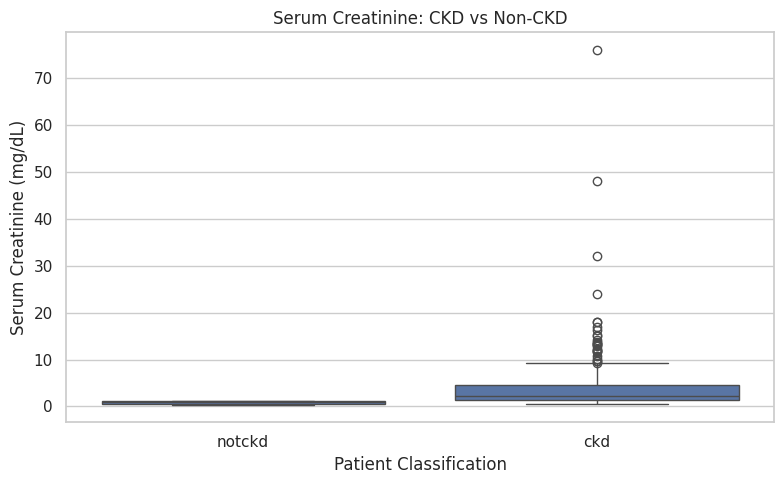

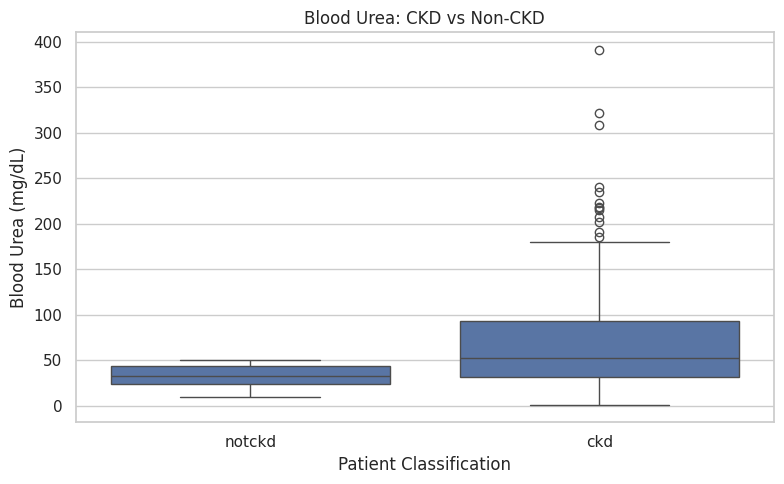

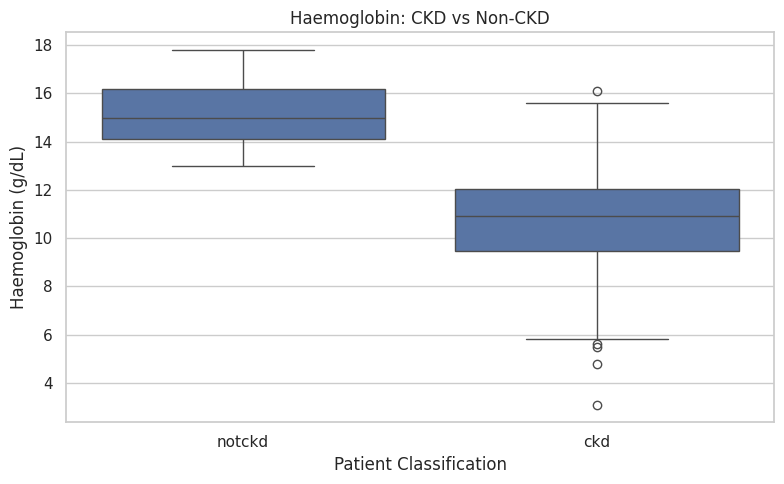

All three graphs created successfully!


In [5]:

# FIX ERROR AND CREATE LABORATORY GRAPHS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# STEP 1: Load dataset again
df = pd.read_csv(
    "/content/CKD_Dataset_Excel_Compatible.csv"
)

# STEP 2: Clean dataset
df_clean = df.copy()

df_clean = df_clean.replace(
    r"^\s*(\?|nan)?\s*$",
    np.nan,
    regex=True
)

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# STEP 3: Convert numerical laboratory results
numeric_columns = [
    'age', 'bp', 'sg', 'al', 'su',
    'bgr', 'bu', 'sc', 'sod', 'pot',
    'hemo', 'pcv', 'wbcc', 'rbcc'
]

for col in numeric_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors='coerce'
        )

print("Dataset loaded successfully!")
print("Total patients:", len(df_clean))

# STEP 4: Create graphs
sns.set_theme(style="whitegrid")

laboratory_tests = {
    "sc": ("Serum Creatinine", "mg/dL"),
    "bu": ("Blood Urea", "mg/dL"),
    "hemo": ("Haemoglobin", "g/dL")
}

for column, (test_name, unit) in laboratory_tests.items():

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df_clean,
        x="class",
        y=column,
        order=["notckd", "ckd"]
    )

    plt.title(f"{test_name}: CKD vs Non-CKD")
    plt.xlabel("Patient Classification")
    plt.ylabel(f"{test_name} ({unit})")

    plt.tight_layout()
    plt.savefig(
        f"{column}_CKD_comparison.png",
        dpi=300
    )
    plt.show()

print("All three graphs created successfully!")


In [6]:

# STEP 5: TRAIN AI MODEL FOR CKD CLASSIFICATION

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Use cleaned dataset
data = df_clean.copy()

# Separate laboratory features and CKD status
X = data.drop(columns=["class"])
y = data["class"].astype(str).str.strip()

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Handle missing laboratory values
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_cols),
    ("categorical", categorical_transformer, categorical_cols)
])

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Build Random Forest AI model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Train AI model
model.fit(X_train, y_train)

# Predict CKD status
y_pred = model.predict(X_test)

# Evaluate performance
print("AI MODEL TRAINING COMPLETED!")

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nMODEL ACCURACY:")
print(round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(
    y_test, y_pred, labels=["notckd", "ckd"]
))


AI MODEL TRAINING COMPLETED!

Training records: 320
Testing records: 80

MODEL ACCURACY:
98.75 %

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

         ckd       0.98      1.00      0.99        50
      notckd       1.00      0.97      0.98        30

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80


CONFUSION MATRIX:
[[29  1]
 [ 0 50]]


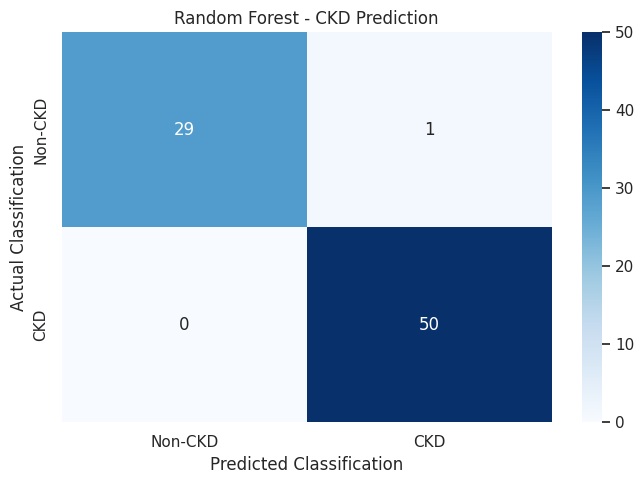

Confusion matrix graph saved successfully!


In [7]:

# STEP 7: CONFUSION MATRIX VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test, y_pred,
    labels=["notckd", "ckd"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-CKD", "CKD"],
    yticklabels=["Non-CKD", "CKD"]
)

plt.title("Random Forest - CKD Prediction")
plt.xlabel("Predicted Classification")
plt.ylabel("Actual Classification")

plt.tight_layout()

plt.savefig(
    "CKD_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix graph saved successfully!")


In [8]:

# STEP 8: COMPARE TWO AI ALGORITHMS

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Random Forest is already trained as "model"

# Build Logistic Regression model
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("scaling", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

# Train Logistic Regression
logistic_model.fit(X_train, y_train)

# Predictions
rf_pred = model.predict(X_test)
lr_pred = logistic_model.predict(X_test)

# Calculate performance metrics
results = []

for name, predictions in [
    ("Random Forest", rf_pred),
    ("Logistic Regression", lr_pred)
]:
    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(
                y_test, predictions, pos_label="ckd"
            ) * 100, 2
        ),
        "Sensitivity (%)": round(
            recall_score(
                y_test, predictions, pos_label="ckd"
            ) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(
                y_test, predictions, pos_label="ckd"
            ) * 100, 2
        )
    })

comparison_df = pd.DataFrame(results)

print("AI MODEL PERFORMANCE COMPARISON")
display(comparison_df)

# Save results for your project report
comparison_df.to_csv(
    "AI_Model_Comparison.csv",
    index=False
)


AI MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Sensitivity (%),F1 Score (%)
0,Random Forest,98.75,98.04,100.0,99.01
1,Logistic Regression,98.75,100.00,98.0,98.99


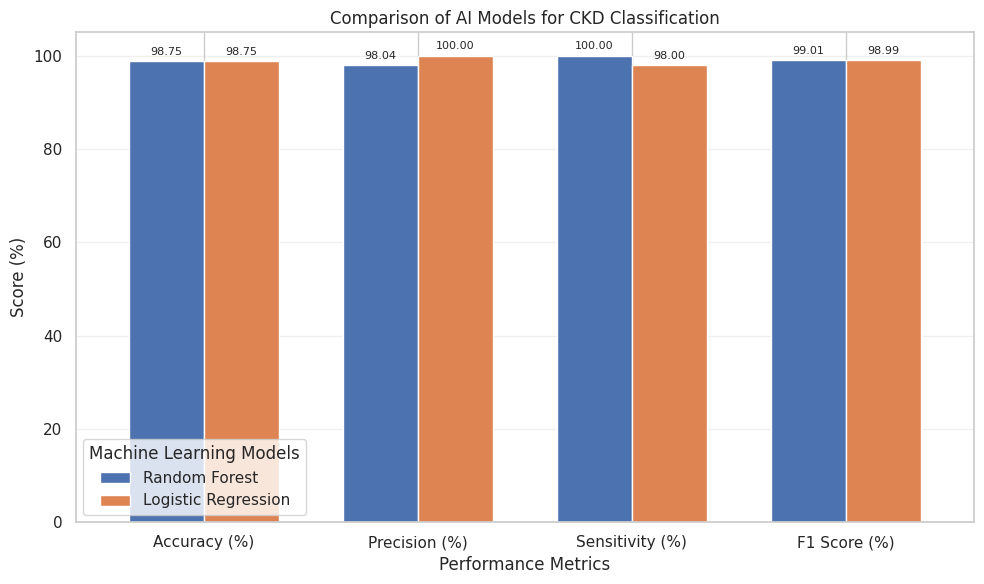

Model comparison graph saved!


In [9]:

# STEP 9: AI MODEL COMPARISON GRAPH

import matplotlib.pyplot as plt

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Sensitivity (%)",
    "F1 Score (%)"
]

graph_data = comparison_df.set_index("Model")[metrics].T

ax = graph_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Comparison of AI Models for CKD Classification")
plt.xlabel("Performance Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title="Machine Learning Models")
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig(
    "AI_Model_Performance_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Model comparison graph saved!")
